### 04. Subgroup SHAP Analysis

This notebook investigates whether the explainability findings from
notebook 03 help explain the subgroup-specific results from notebook 02.
Specifically, notebook 02 found that the learned correction significantly
improves classification for Normal EF but not for HFrEF or HFmrEF, while
notebook 03 found that volume_ratio — the dominant predictor — has a
non-monotonic effect on the correction, peaking around 0.4-0.5 and
diminishing at both extremes.

This notebook tests whether patients in different clinical categories fall
into different regions of that curve, which would offer a mechanistic
explanation for why the correction helps some categories more than others.

Given the small sample size for HFmrEF (n≈8 in TEST), formal statistical
comparison is restricted to Normal EF vs. HFrEF; HFmrEF is included only
descriptively.

All analyses are performed on the **TEST split**, consistent with
notebooks 02 and 03.

- **Inputs:** `models/gb_correction.joblib`, `data/processed/inference_with_corrections.csv`
- **Outputs:** subgroup dependence plot and SHAP distribution comparison saved to `figures/`.

#### Load model, data, and clinical classes

In [2]:
import sys
sys.path.append('...')

import pandas as pd
import joblib
import numpy as np
import shap
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white", font_scale=1.0)

reg = joblib.load("../models/gb_correction.joblib")
data = pd.read_csv("../data/processed/inference_with_corrections.csv")

test = data[data['split'] == 'TEST'].copy()
features = ['volume_ratio', 'length_ratio', 'dice_overlap_std']
X_test = test[features]

def classify_ef(ef):
    if ef <= 40:
        return 'HFrEF'
    elif ef <= 49:
        return 'HFmrEF'
    elif ef <= 74:
        return 'Normal'
    else:
        return 'HCM'

test['true_class'] = test['true_ef'].apply(classify_ef)
test['true_class'].value_counts()

true_class
Normal    333
HFrEF      27
HFmrEF      8
Name: count, dtype: int64

Sample sizes are highly imbalanced across categories (Normal: n=333,
HFrEF: n=27, HFmrEF: n=8). Comparisons involving HFrEF should be
interpreted as exploratory given its limited sample size, and HFmrEF
(n=8) is excluded from formal statistical testing entirely, as noted
above. This does not invalidate the comparison but confidence in the HFrEF result is
necessarily lower than in Normal EF.

#### Volume ratio dependence by clinical category

The dependence plot for volume_ratio (notebook 03) showed a non-monotonic
effect: strongly negative SHAP values for low ratios, a positive plateau
around 0.4-0.5, and a decline for higher ratios. Here, the same plot is
recolored by true clinical category instead of by feature interaction, to
check whether patients from different categories fall into different
regions of this curve.

Sample sizes are highly imbalanced (Normal: n=333, HFrEF: n=27,
HFmrEF: n=8); HFrEF and especially HFmrEF results should be read as
exploratory.

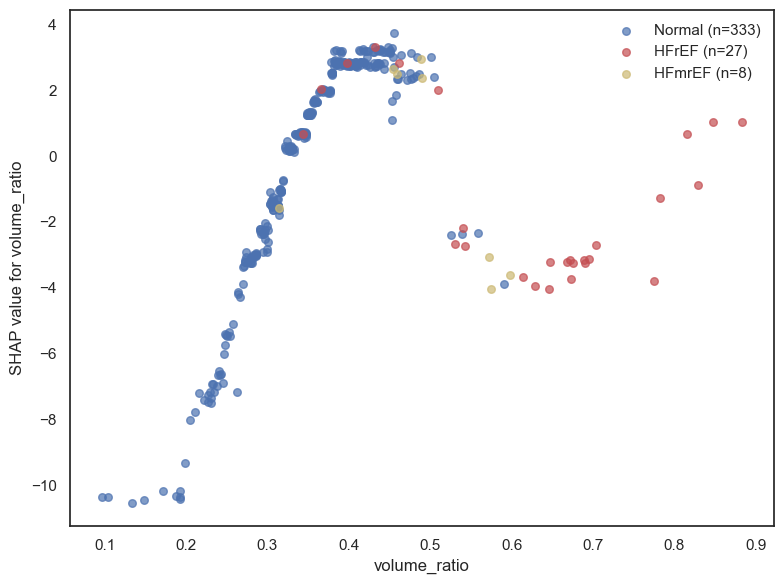

In [4]:
explainer = shap.TreeExplainer(reg)
shap_values = explainer.shap_values(X_test)

shap_volume = shap_values[:, features.index('volume_ratio')]
volume_ratio_vals = X_test['volume_ratio'].values

palette = {'Normal': '#4C72B0', 'HFrEF': '#C44E52', 'HFmrEF': '#CCB974', 'HCM': '#55A868'}

fig, ax = plt.subplots(figsize=(8, 6))
for cls in ['Normal', 'HFrEF', 'HFmrEF', 'HCM']:
    mask = test['true_class'].values == cls
    if mask.sum() == 0:
        continue
    ax.scatter(
        volume_ratio_vals[mask], shap_volume[mask],
        label=f'{cls} (n={mask.sum()})',
        color=palette[cls], alpha=0.7, s=30
    )

ax.set_xlabel('volume_ratio')
ax.set_ylabel('SHAP value for volume_ratio')
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig('../figures/shap_volume_by_class.png', dpi=200, bbox_inches='tight')
plt.show()

In [7]:
test.groupby('true_class')['volume_ratio'].describe()[['count', 'mean', '25%', '50%', '75%']]

,count,mean,25%,50%,75%
true_class,,,,,
HFmrEF,8.0,0.493803,0.458210,0.489415,0.572545
HFrEF,27.0,0.631870,0.535153,0.668276,0.699468
Normal,333.0,0.349416,0.304695,0.348048,0.402065


Median volume_ratio increases clearly across categories: Normal (0.348),
HFmrEF (0.490), HFrEF (0.668), with little overlap between Normal and
HFrEF. This matches the clinical meaning of volume_ratio (systolic/diastolic
volume): a weaker heart contracts less, so the ratio is higher.

On the SHAP curve, this means HFrEF patients mostly fall in the
high-ratio region where the correction model is less stable, while Normal
patients sit mostly in the stable middle plateau. This may explain why the
correction helps Normal EF classification (notebook 02) but not HFrEF:
HFrEF cases tend to land where the model is less reliable.

#### Statistical comparison: SHAP distributions (Normal vs. HFrEF)

To formally test whether the SHAP value distribution for volume_ratio
differs between Normal and HFrEF patients, a Mann-Whitney U test is used
(non-parametric, appropriate given no normality assumption and unequal
group sizes). HFmrEF (n=8) is excluded from formal testing due to its
very small sample size; it is reported descriptively only.

- H0: the SHAP value distributions for volume_ratio are the same between
  Normal and HFrEF
- H1: the distributions differ (two-tailed)
- alpha = 0.05

In [10]:
from scipy.stats import mannwhitneyu

shap_normal = shap_volume[test['true_class'].values == 'Normal']
shap_hfref = shap_volume[test['true_class'].values == 'HFrEF']
shap_hfmref = shap_volume[test['true_class'].values == 'HFmrEF']

stat, p_value = mannwhitneyu(shap_normal, shap_hfref, alternative='two-sided')

print(f"Normal median SHAP: {np.median(shap_normal):.3f}")
print(f"HFrEF median SHAP:  {np.median(shap_hfref):.3f}")
print(f"HFmrEF median SHAP (descriptive only, n=8): {np.median(shap_hfmref):.3f}")
print(f"\nMann-Whitney U = {stat:.1f}, p = {p_value:.4f}")
print("reject H0" if p_value < 0.05 else "-> fail to reject H0")

Normal median SHAP: 0.703
HFrEF median SHAP:  -2.710
HFmrEF median SHAP (descriptive only, n=8): 0.403

Mann-Whitney U = 5988.0, p = 0.0041
reject H0


The Mann-Whitney U test confirms a statistically significant difference in
SHAP value distributions for volume_ratio between Normal and HFrEF
(U = 5988.0, p = 0.0041). Normal patients have a positive median SHAP
value (0.703), consistent with falling in the stable plateau region, while
HFrEF patients have a negative median (-2.710), consistent with falling in
the descending, less stable region of the curve. HFmrEF shows an
intermediate median (0.403, n=8, descriptive only).

Patients across clinical categories occupy different regions of the
volume_ratio SHAP curve: Normal EF cases concentrate in the stable
plateau (median SHAP 0.703), while HFrEF cases fall in the unstable,
descending region (median SHAP -2.710), a difference confirmed by the
Mann-Whitney test (p = 0.0041). This offers a plausible explanation for
the subgroup-specific result in notebook 02 — the correction significantly
improves Normal EF classification but not HFrEF.